# IMPORT

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# DEFINE FOLDERS

In [2]:
DATASET_INPUT_FOLDER = Path("correlated_data_csv")
PLOT_FOLDER = Path("plots")

folders = [DATASET_INPUT_FOLDER, PLOT_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# LOAD DATA

In [3]:
df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/correlated_data_2.csv")
df.head(5)

,name,stationcode,ebike,mechanical,latitude,longitude,duedate,numbikesavailable,numdocksavailable,capacity,...,is_returning,code_insee_commune,weather_time,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code,source_file
0,Cassini - Denfert-Rochereau,14111.0,2.0,0.0,48.837526,2.336035,2025-11-04T03:25:04+00:00,2,22,25.0,...,OUI,75056.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
1,Basilique,32017.0,5.0,1.0,48.936269,2.358867,2025-11-04T03:21:03+00:00,6,16,22.0,...,OUI,93066.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
2,Charonne - Robert et Sonia Delaunay,11104.0,1.0,1.0,48.855908,2.392571,2025-11-04T03:29:35+00:00,2,18,20.0,...,OUI,75056.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
3,Lacépède - Monge,5110.0,1.0,6.0,48.843893,2.351966,2025-11-04T03:30:23+00:00,7,15,23.0,...,OUI,75056.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
4,Saint-Romain - Cherche-Midi,6108.0,2.0,2.0,48.847082,2.321375,2025-11-04T03:28:05+00:00,4,11,17.0,...,OUI,75056.0,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json


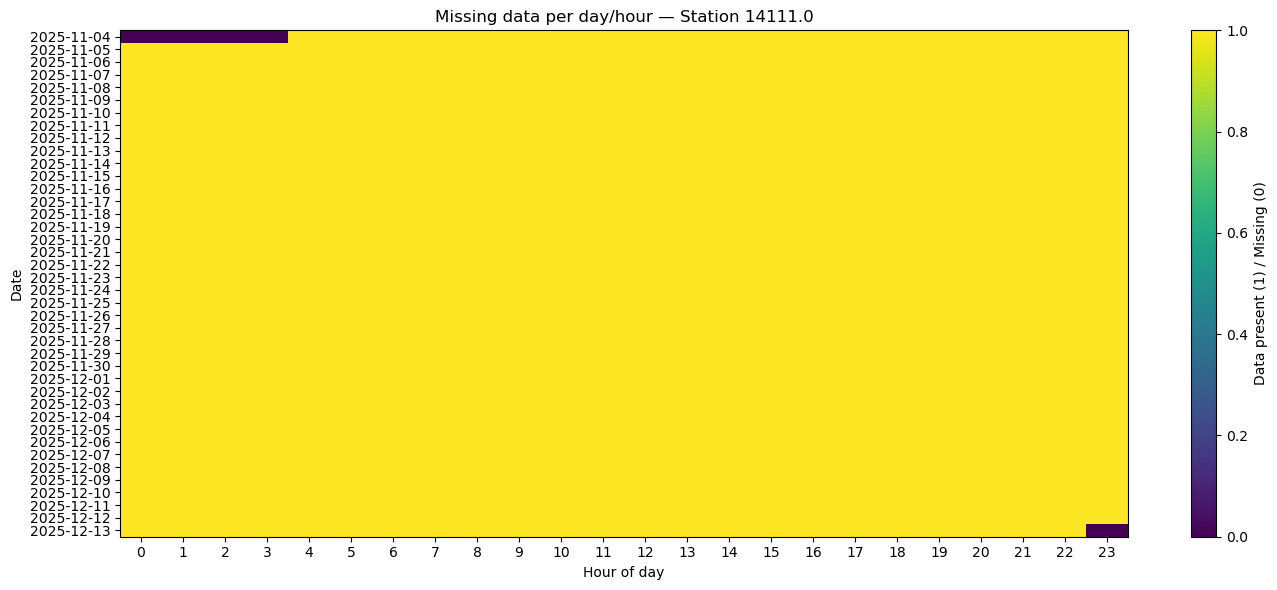

In [4]:
df["weather_time"] = pd.to_datetime(df["weather_time"], errors="coerce")
df = df.dropna(subset=["stationcode", "weather_time"])

# =========================
# Choose station
# =========================
station_id = df["stationcode"].iloc[0]  # change manually if you want
df_s = df[df["stationcode"] == station_id].copy()

# =========================
# Build time grid
# =========================
df_s["date"] = df_s["weather_time"].dt.date
df_s["hour"] = df_s["weather_time"].dt.hour

dates = sorted(df_s["date"].unique())
hours = np.arange(24)

presence = np.zeros((len(dates), 24))

for i, d in enumerate(dates):
    hours_present = df_s[df_s["date"] == d]["hour"].unique()
    presence[i, hours_present] = 1

# =========================
# Plot
# =========================
plt.figure(figsize=(14, 6))
plt.imshow(presence, aspect="auto")
plt.yticks(range(len(dates)), dates)
plt.xticks(range(24), range(24))
plt.xlabel("Hour of day")
plt.ylabel("Date")
plt.title(f"Missing data per day/hour — Station {station_id}")
plt.colorbar(label="Data present (1) / Missing (0)")
plt.tight_layout()
plt.show()

# SAVE ALL OF THEM

In [ ]:
for station_id, df_s in df.groupby("stationcode"):
    df_s = df_s.copy()
    df_s["date"] = df_s["weather_time"].dt.date
    df_s["hour"] = df_s["weather_time"].dt.hour

    dates = sorted(df_s["date"].unique())
    if len(dates) < 3:
        continue  # skip tiny stations

    presence = np.zeros((len(dates), 24))

    for i, d in enumerate(dates):
        hours_present = df_s[df_s["date"] == d]["hour"].unique()
        presence[i, hours_present] = 1

    plt.figure(figsize=(14, 6))
    plt.imshow(presence, aspect="auto")
    plt.xticks(range(24), range(24))
    plt.yticks([])
    plt.xlabel("Hour of day")
    plt.title(f"Station {station_id} — Missing data pattern")
    plt.colorbar(label="Data present (1) / Missing (0)")
    plt.tight_layout()
    plt.savefig(f"{PLOT_FOLDER}/station_{int(station_id)}.png")
    plt.close()

print("Missing-data plots saved for all stations.")

✅ Missing-data plots saved for all stations.
